In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("ab_data.csv")
print(df.head())

   user_id                   timestamp      group landing_page  converted
0   851104  2017-01-21 22:11:48.556739    control     old_page          0
1   804228  2017-01-12 08:01:45.159739    control     old_page          0
2   661590  2017-01-11 16:55:06.154213  treatment     new_page          0
3   853541  2017-01-08 18:28:03.143765  treatment     new_page          0
4   864975  2017-01-21 01:52:26.210827    control     old_page          1


In [2]:
print(df.shape)

(294478, 5)


In [3]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 294478 entries, 0 to 294477
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   user_id       294478 non-null  int64 
 1   timestamp     294478 non-null  object
 2   group         294478 non-null  object
 3   landing_page  294478 non-null  object
 4   converted     294478 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 11.2+ MB
None


In [4]:
print(df.isnull().sum())

user_id         0
timestamp       0
group           0
landing_page    0
converted       0
dtype: int64


In [5]:
print(df.duplicated().sum())

0


In [6]:
print(df["group"].value_counts())

group
treatment    147276
control      147202
Name: count, dtype: int64


In [7]:
print(df["landing_page"].value_counts())

landing_page
old_page    147239
new_page    147239
Name: count, dtype: int64


In [8]:

## Cleaning the data
cleaning_log = []
original_rows = len(df)

def log_cleaning_step(step, before, after):
    cleaning_log.append({
        "Step": step,
        "Rows Before": before,
        "Rows After": after,
        "Rows Removed": before - after
    })

before = len(df)
df = df.drop_duplicates(subset="user_id", keep="first").copy()
log_cleaning_step("Remove duplicate users", before, len(df))

before = len(df)
valid_groups = ["control", "treatment"]
valid_pages = ["old_page", "new_page"]

df = df[
    df["group"].isin(valid_groups) &
    df["landing_page"].isin(valid_pages)
].copy()
log_cleaning_step("Validate groups and pages", before, len(df))

before = len(df)
df = df[
    ((df["group"] == "control") &
     (df["landing_page"] == "old_page")) |
    ((df["group"] == "treatment") &
     (df["landing_page"] == "new_page"))
].copy()
log_cleaning_step("Validate assignments", before, len(df))

before = len(df)
df["converted"] = pd.to_numeric(
    df["converted"], errors="coerce"
)
df = df[df["converted"].isin([0, 1])].copy()
log_cleaning_step("Validate conversions", before, len(df))

cleaning_log_df = pd.DataFrame(cleaning_log)
display(cleaning_log_df)

print("Original rows:", original_rows)
print("Cleaned shape:", df.shape)
print("Total rows removed:", original_rows - len(df))

print(
    df.groupby("group")["converted"]
      .agg(["count", "sum", "mean"])
)


,Step,Rows Before,Rows After,Rows Removed
0,Remove duplicate users,294478,290584,3894
1,Validate groups and pages,290584,290584,0
2,Validate assignments,290584,288540,2044
3,Validate conversions,288540,288540,0


Original rows: 294478
Cleaned shape: (288540, 5)
Total rows removed: 5938
            count    sum      mean
group                             
control    144226  17349  0.120290
treatment  144314  17134  0.118727


In [9]:
# srm
from scipy.stats import chisquare

observed = (df["group"].value_counts().reindex(["control", "treatment"], fill_value=0).to_numpy())
total = observed.sum()
excepted = np.array([total*0.5, total*0.5])
chi2_stat, srm_p_value = chisquare(f_obs = observed, f_exp = excepted)

print("Observed counts:", observed)
print(f"SRM(Sample Ratio Mismatch) p-value: {srm_p_value:.6f}")

if srm_p_value < 0.001:
    print("WARNING: Possible sample ratio mismatch. Investigate before interpreting results.")
else:
    print("No statistically significant sample ratio mismatch detected.")

Observed counts: [144226 144314]
SRM(Sample Ratio Mismatch) p-value: 0.869869
No statistically significant sample ratio mismatch detected.


In [10]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

baseline_rate = 0.10
mde = 0.02
alpha = 0.05
target_power = 0.80
target_rate = baseline_rate + mde

if target_rate>=1:
    raise ValueError("Target conversion rate must be below 100%")

effect_size = abs(proportion_effectsize(baseline_rate, target_rate))
power_model = NormalIndPower()
required_per_group = power_model.solve_power(
    effect_size=effect_size,
    power=target_power,
    alpha=alpha,
    ratio=1.0,
    alternative="two-sided"
)
required_per_group = int(np.ceil(required_per_group))

print("POWER CALCULATOR")
print("------------------------------------")
print(f"Baseline conversion:    {baseline_rate:.2%}")
print(f"Target conversion:      {target_rate:.2%}")
print(f"Absolute MDE:           {mde:.2%}")
print(f"Significance level:     {alpha:.0%}")
print(f"Target Power:           {target_power:.0%}")
print(f"Required per group:     {required_per_group:,}")
print(f"Total sample size:      {2*required_per_group:,}")

POWER CALCULATOR
------------------------------------
Baseline conversion:    10.00%
Target conversion:      12.00%
Absolute MDE:           2.00%
Significance level:     5%
Target Power:           80%
Required per group:     3,835
Total sample size:      7,670


In [11]:
from statsmodels.stats.proportion import proportions_ztest

control = df[df["group"]=="control"]
treatment = df[df["group"]=="treatment"]

successes = np.array([
    control["converted"].sum(),
    treatment["converted"].sum()
])
sample_size = np.array([
    len(control),
    len(treatment)
])
z_stat, p_value = proportions_ztest(
    count = successes,
    nobs = sample_size,
    alternative="two-sided"
)
print(f"z-statistic: {z_stat:.4f}")
print(f"p-test: {p_value:.6f}")
alpha = 0.05
if p_value<alpha:
    print("Statistically significant difference")
else:
    print("Insufficient evidence of a difference")

z-statistic: 1.2942
p-test: 0.195584
Insufficient evidence of a difference


In [12]:
summary = (df.groupby("group")["converted"].agg(users="count", conversions= "sum", rate = "mean"))
print(summary)
print("--------------------------------------------------")

control_rate = summary.loc["control", "rate"]
treatment_rate = summary.loc["treatment", "rate"]
absolute_lift = treatment_rate - control_rate
relative_life = absolute_lift/control_rate * 100

print(f"Control Conversion:     {control_rate:.2%}")
print(f"Treatment Conversion:   {treatment_rate:.2%}")
print(f"Absolute lift:          {absolute_lift:.2%}")
print(f"Relative lift:          {relative_life:.2%}")

            users  conversions      rate
group                                   
control    144226        17349  0.120290
treatment  144314        17134  0.118727
--------------------------------------------------
Control Conversion:     12.03%
Treatment Conversion:   11.87%
Absolute lift:          -0.16%
Relative lift:          -129.95%


In [13]:
from statsmodels.stats.proportion import confint_proportions_2indep

control_success = int(control["converted"].sum())
treatment_success = int(treatment["converted"].sum())

ci_low, ci_high = confint_proportions_2indep(
    count1=treatment_success,
    nobs1=len(treatment),
    count2=control_success,
    nobs2=len(control),
    method="newcomb",
    compare="diff",
    alpha=0.05
)

print(f"Estimated absolute lift: {absolute_lift:.4f}")
print(f"95% CI: [{ci_low:.4%}, {ci_high:.4%}]")

Estimated absolute lift: -0.0016
95% CI: [-0.3930%, 0.0804%]


In [14]:
# Business conclusion
print("=" * 60)
print("BUSINESS CONCLUSION")
print("=" * 60)

print(f"Control conversion rate:   {control_rate:.2%}")
print(f"Treatment conversion rate: {treatment_rate:.2%}")
print(f"Absolute lift:             {absolute_lift:.2%}")
print(f"Relative lift:             {relative_life:.2f}%")
print(f"95% confidence interval:   [{ci_low:.2%}, {ci_high:.2%}]")
print(f"P-value:                   {p_value:.6f}")

if p_value < alpha:
    if absolute_lift > 0:
        print(
            "\nThe treatment has a statistically significant "
            "positive conversion-rate effect. Consider a staged "
            "rollout after checking data quality and guardrail metrics."
        )
    elif absolute_lift < 0:
        print(
            "\nThe treatment has a statistically significant "
            "negative conversion-rate effect. Do not roll it out "
            "without investigating the decline."
        )
    else:
        print("\nNo observed difference in conversion rates.")
else:
    print(
        "\nThe experiment did not establish a statistically "
        "significant difference. This does not prove that the "
        "two versions are equivalent. Review the confidence "
        "interval and power before deciding next steps."
    )

print(
    "\nFinal decision should also account for the SRM check, "
    "sample quality, experiment duration, and business guardrails."
)


BUSINESS CONCLUSION
Control conversion rate:   12.03%
Treatment conversion rate: 11.87%
Absolute lift:             -0.16%
Relative lift:             -1.30%
95% confidence interval:   [-0.39%, 0.08%]
P-value:                   0.195584

The experiment did not establish a statistically significant difference. This does not prove that the two versions are equivalent. Review the confidence interval and power before deciding next steps.

Final decision should also account for the SRM check, sample quality, experiment duration, and business guardrails.


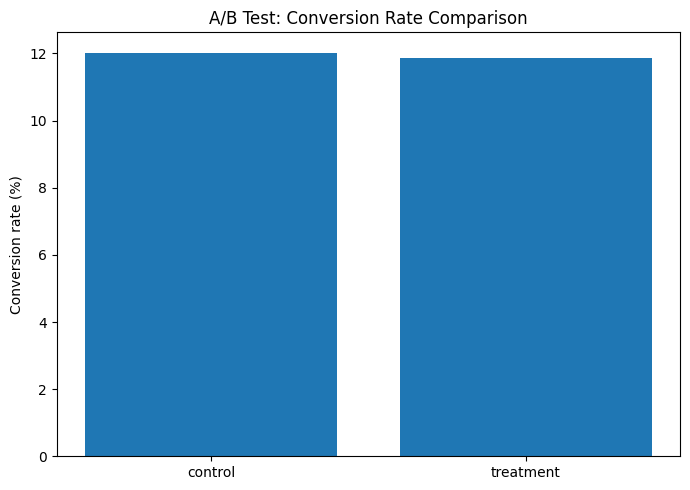

In [15]:
import matplotlib.pyplot as plt

rates = summary["rate"]*100

plt.figure(figsize=(7, 5))
plt.bar(rates.index, rates.values)
plt.ylabel("Conversion rate (%)")
plt.title("A/B Test: Conversion Rate Comparison")
plt.tight_layout()
plt.show()